## Project Day 03

### Generate .LAS file with realistic curves.

#### Keith R. Holdaway FGS

### What Makes This File "Very Realistic":

### Multiple Scales of Variation:

#### Trend: Large-scale shale-sand-shale sequence.

#### Medium-Scale: Sine waves representing individual depositional packages.

#### High-Frequency: Fine "wiggles" (sin(80 * pi * scale)) mimicking real tool response and thin bedding.

#### Random Noise: Gaussian and log-normal noise added to all curves.

### Petrophysical Consistency:

#### GR and RT Relationship: The resistivity curve is built to generally anti-correlate with Gamma Ray, as clean sands (low GR) should have higher resistivity.

#### Porosity Derivation: The Density (RHOB) and Neutron (NPHI) curves are mathematically derived from the total porosity (PHIT), which itself is based on the shale volume (VSH) calculated from Gamma Ray. This creates a fundamental physical link between all curves.

#### Crossover: The Neutron-Density crossover is naturally created by adding a shale effect to the Neutron curve (nphi_shale_effect).

### Realistic Hydrocarbon Response:

A clear pay zone is inserted where resistivity dramatically increases (RT * 8 + 15).

A "shoulder effect" is modeled around the pay zone, a common real-world observation.

Porosity is slightly enhanced in the pay zone.

High Resolution: The step = 0.125 creates data every 12.5 cm, which is standard for modern tools, resulting in over 800 data points and a very "wiggly" appearance.

In [ ]:
#pip install welly

In [1]:
import numpy as np
import lasio
import pandas as pd

# --- Configuration ---
output_filename = 'well_42-101.las'
top_depth = 2500.0
base_depth = 2600.0
step = 0.125  # 12.5 cm resolution for high-resolution data
np.random.seed(42)  # For reproducible results

# Create depth array
depth = np.arange(top_depth, base_depth + step, step)
n_samples = len(depth)

# --- 1. Define the Geological Background Trend ---
scale = (depth - top_depth) / (base_depth - top_depth)

# Main GR trend
gr_trend = 15 + 70 * np.sin(3 * np.pi * scale - np.pi/2)**2
# Main Resistivity trend (log scale)
rt_trend = 0.5 + 2.5 * np.sin(3 * np.pi * scale - np.pi/2)**2
rt_trend = 10**rt_trend

# --- 2. Add Medium-Scale Geological Features ---
gr_med = (8 * np.sin(20 * np.pi * scale) + 
          5 * np.sin(31 * np.pi * scale) +
          3 * np.sin(47 * np.pi * scale))

rt_med = (0.15 * np.sin(20 * np.pi * scale + 0.5) + 
          0.1 * np.sin(31 * np.pi * scale + 0.2) +
          0.08 * np.sin(47 * np.pi * scale + 1.1))
rt_med = 10**rt_med

# --- 3. Add High-Frequency "Wiggles" and Noise ---
gr_hf = 2 * np.sin(80 * np.pi * scale)
gr_noise = np.random.normal(0, 1.0, n_samples)

rt_hf = 0.05 * np.sin(75 * np.pi * scale + 0.7)
rt_noise = np.random.lognormal(mean=0.0, sigma=0.03, size=n_samples)

# --- 4. Combine All Components for GR and RT ---
GR = gr_trend + gr_med + gr_hf + gr_noise
RT = rt_trend * rt_med * rt_hf * rt_noise

# --- 5. Create Porosity Curves Linked to GR & RT ---
vsh_gr = (GR - GR.min()) / (GR.max() - GR.min())
vsh_gr = np.clip(vsh_gr, 0, 1)

phi_trend = 0.35 * (1 - vsh_gr)
phi_var = 0.05 * np.sin(25 * np.pi * scale) + 0.03 * np.sin(60 * np.pi * scale)
phi_noise = np.random.normal(0, 0.01, n_samples)
PHIT = np.clip(phi_trend + phi_var + phi_noise, 0.01, 0.36)

RHOB = 2.65 - PHIT * (2.65 - 1.0)
RHOB_noise = np.random.normal(0, 0.02, n_samples)
RHOB += RHOB_noise

nphi_shale_effect = 0.15 * vsh_gr
nphi_noise = np.random.normal(0, 0.008, n_samples)
NPHI = np.clip(PHIT + nphi_shale_effect + nphi_noise, 0.01, 0.5)

DPHI = (2.65 - RHOB) / (2.65 - 1.0)

# --- 6. Create a Hydrocarbon-Bearing Zone ---
pay_zone_mask = (depth >= 2538.0) & (depth <= 2548.0)
RT[pay_zone_mask] = RT[pay_zone_mask] * 8 + 15

shoulder_mask = ((depth >= 2535.0) & (depth < 2538.0)) | ((depth > 2548.0) & (depth <= 2551.0))
RT[shoulder_mask] = RT[shoulder_mask] * 1.7

PHIT[pay_zone_mask] = PHIT[pay_zone_mask] * 1.1
RHOB[pay_zone_mask] = 2.65 - PHIT[pay_zone_mask] * (2.65 - 1.0) + np.random.normal(0, 0.015, np.sum(pay_zone_mask))
DPHI[pay_zone_mask] = (2.65 - RHOB[pay_zone_mask]) / (2.65 - 1.0)

# --- 7. Create the DataFrame ---
df = pd.DataFrame({
    'DEPT': depth,
    'GR': GR,
    'RT': RT,
    'NPHI': NPHI,
    'RHOB': RHOB,
    'DPHI': DPHI
})

# --- 8. Create and Write the LAS File (UPDATED FOR MODERN LASIO) ---
las = lasio.LASFile()

# Add well information using tuples: (value, unit)
las.well['STRT'] = (top_depth, 'M')
las.well['STOP'] = (base_depth, 'M')
las.well['STEP'] = (step, 'M')
las.well['NULL'] = (-999.25, '')
las.well['COMP'] = 'SYNTHETIC OIL CO.'
las.well['WELL'] = 'Well 42-101'
las.well['FLD'] = 'Example Field'
las.well['SRVC'] = 'AI-GENERATED'
las.well['DATE'] = '12-May-2024'
las.well['UWI'] = '123456789012'

# Add curve information - value array, then unit
las.append_curve('DEPT', df['DEPT'].values, unit='M')
las.append_curve('GR', df['GR'].values, unit='GAPI')
las.append_curve('RT', df['RT'].values, unit='OHMM')
las.append_curve('NPHI', df['NPHI'].values, unit='V/V')
las.append_curve('RHOB', df['RHOB'].values, unit='G/C3')
las.append_curve('DPHI', df['DPHI'].values, unit='V/V')

# Add parameter section - FIXED: Use HeaderItem objects instead of tuples
from lasio import HeaderItem
las.params['BHT'] = HeaderItem('BHT', value=45.0, unit='DEGC')
las.params['RMF'] = HeaderItem('RMF', value=0.06, unit='OHMM')

# Add a comment
las.other = 'NOTE: This is a highly realistic synthetically generated LAS file for petrophysical training.'

# Write the file
las.write(output_filename, version=2.0)
print(f"Successfully generated realistic LAS file: {output_filename}")
print(f"Number of depth points: {n_samples}")
print(f"Curves: DEPT, GR, RT, NPHI, RHOB, DPHI")

Successfully generated realistic LAS file: well_42-101.las
Number of depth points: 801
Curves: DEPT, GR, RT, NPHI, RHOB, DPHI


### Python Basics #1 - Variables and Lists

In [2]:
well_name = "well_42-101"
depth_top = 2550.5
porosity = 0.24  # That's 24%!
has_oil = True

#### A List holds a sequence of things.

In [3]:
gamma_ray_readings = [65.2, 68.1, 71.5, 69.8, 65.0]
depths = [2550, 2550.5, 2551, 2551.5, 2552]

### Python Basics #2 - The pandas DataFrame

In [4]:
import pandas as pd

df = pd.DataFrame({
    'DEPT': [2550.0, 2550.5, 2551.0],
    'GR': [65.2, 68.1, 71.5],
    'RHOB': [2.45, 2.48, 2.52],
    'NPHI': [0.24, 0.22, 0.19],
    'RT': [20.1, 18.5, 15.2]
})
print(df)

     DEPT    GR  RHOB  NPHI    RT
0  2550.0  65.2  2.45  0.24  20.1
1  2550.5  68.1  2.48  0.22  18.5
2  2551.0  71.5  2.52  0.19  15.2


### The Magic Trick: Reading a LAS File

#### This is why we're here. The lasio library makes it trivial.

In [5]:
# First, we import our tools
import lasio
import pandas as pd

# Read the LAS file
las = lasio.read('well_42-101.las')

# Convert it to a pandas DataFrame
df = las.df()

# Set the depth as a regular column instead of the index
df.reset_index(inplace=True)

# Show the first 5 rows of our new data table
print(df.tail())

         DEPT        GR        RT     NPHI     RHOB     DPHI
796  2599.500  84.78955  25.75016  0.16726  2.58518  0.03929
797  2599.625  85.47176   9.36627  0.17130  2.58619  0.03867
798  2599.750  84.85023  -5.41651  0.16617  2.59853  0.03119
799  2599.875  84.93208 -19.15835  0.18038  2.57722  0.04411
800  2600.000  85.93828 -32.11190  0.15846  2.61281  0.02254


### A First Plot: The Gamma Ray Log

#### Let's make a simple log plot to see our data.

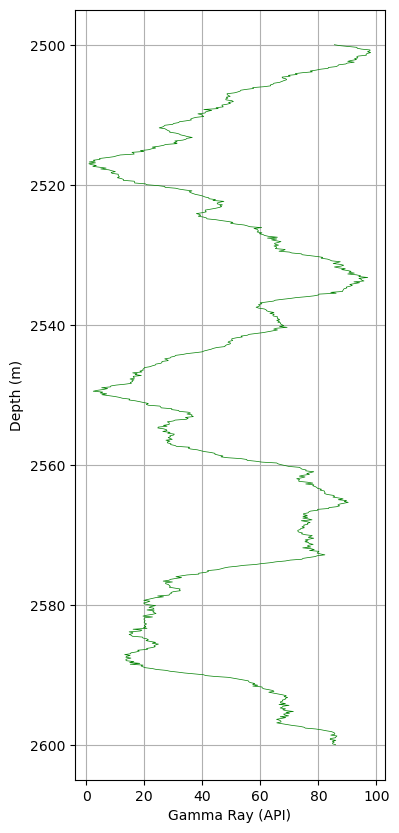

In [6]:
import matplotlib.pyplot as plt

# Create a figure and axis
fig, ax = plt.subplots(figsize=(4, 10)) # (width, height)

# Plot GR vs Depth
ax.plot(df['GR'], df['DEPT'], color='green', linewidth=0.5)

# Invert the depth axis so deeper is lower
ax.invert_yaxis()

# Add labels and a grid
ax.set_ylabel('Depth (m)')
ax.set_xlabel('Gamma Ray (API)')
ax.grid(True)

plt.show()

### The Petrophysical Triple Combo Plot

#### Now let's build a standard plot. We use matplotlib to create multiple subplots.

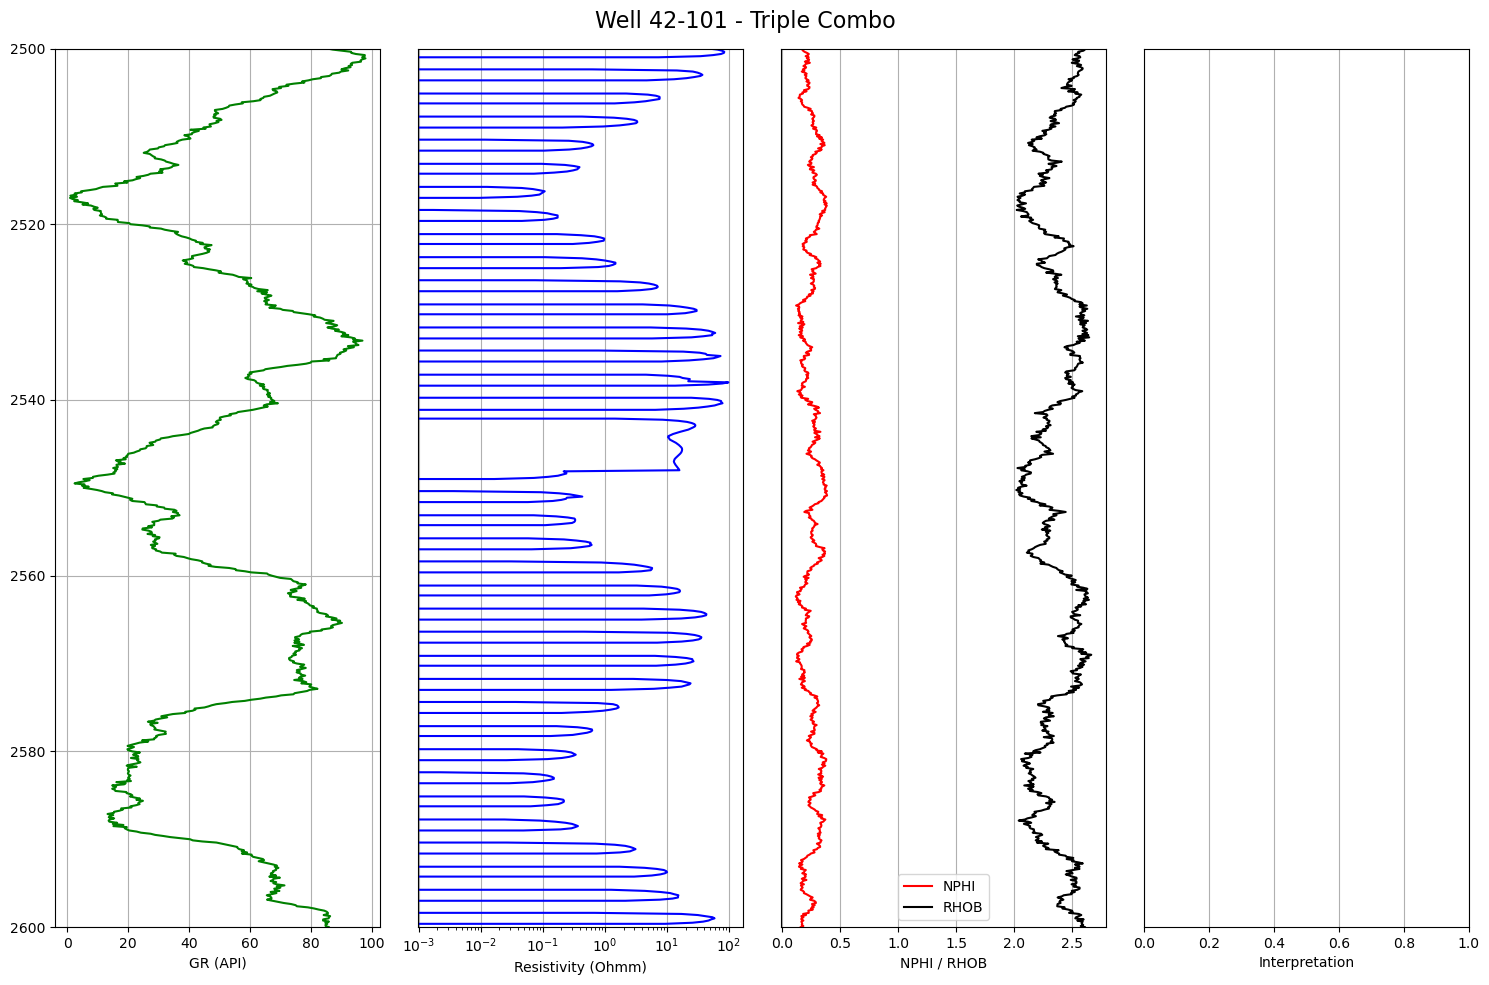

In [7]:
# Create a figure with 1 row and 4 columns of subplots
fig, axes = plt.subplots(1, 4, figsize=(15, 10))
fig.suptitle('Well 42-101 - Triple Combo', fontsize=16)

# Share the same depth (Y) axis across all plots
for ax in axes:
    ax.invert_yaxis()
    ax.set_ylim(df['DEPT'].max(), df['DEPT'].min())
    ax.grid(True)
    ax.yaxis.set_visible(False) # Turn off depth labels on all...
axes[0].yaxis.set_visible(True) # ...except the first plot

# 1. Track 1: Gamma Ray
axes[0].plot(df['GR'], df['DEPT'], color='green')
axes[0].set_xlabel('GR (API)')

# 2. Track 2: Resistivity
axes[1].plot(df['RT'], df['DEPT'], color='blue')
axes[1].set_xlabel('Resistivity (Ohmm)')
axes[1].set_xscale('log') # Make it a logarithmic scale

# 3. Track 3: Density Porosity
axes[2].plot(df['NPHI'], df['DEPT'], color='red', label='NPHI')
axes[2].plot(df['RHOB'], df['DEPT'], color='black', label='RHOB')
axes[2].set_xlabel('NPHI / RHOB')
axes[2].legend()

# 4. Track 4: Leave empty for your own interpretation!
axes[3].set_xlabel('Interpretation')

plt.tight_layout()
plt.show()

### Simple Analysis: Calculating Shale Volume

#### Let's do something analytical. A simple linear Vshale calculation from Gamma Ray.

### Your Final Project: The Petrophysicist's Report

#### How to Use This Project on Different Wells:
Change the Input File: Simply change 'well_42-101.csv' to your new well's filename.

Adjust Petrophysical Parameters: Modify rho_ma, rho_fl, and the GR percentiles based on the new geological formation.

Experiment with Clusters: Change n_clusters=5 to different values to see how the facies classification changes.

Add New Logs: If your new well has additional logs (e.g., 'PEF', 'DTS'), add them to the features list for the ML clustering.

GR min (clean): 11.4, GR max (shale): 89.8


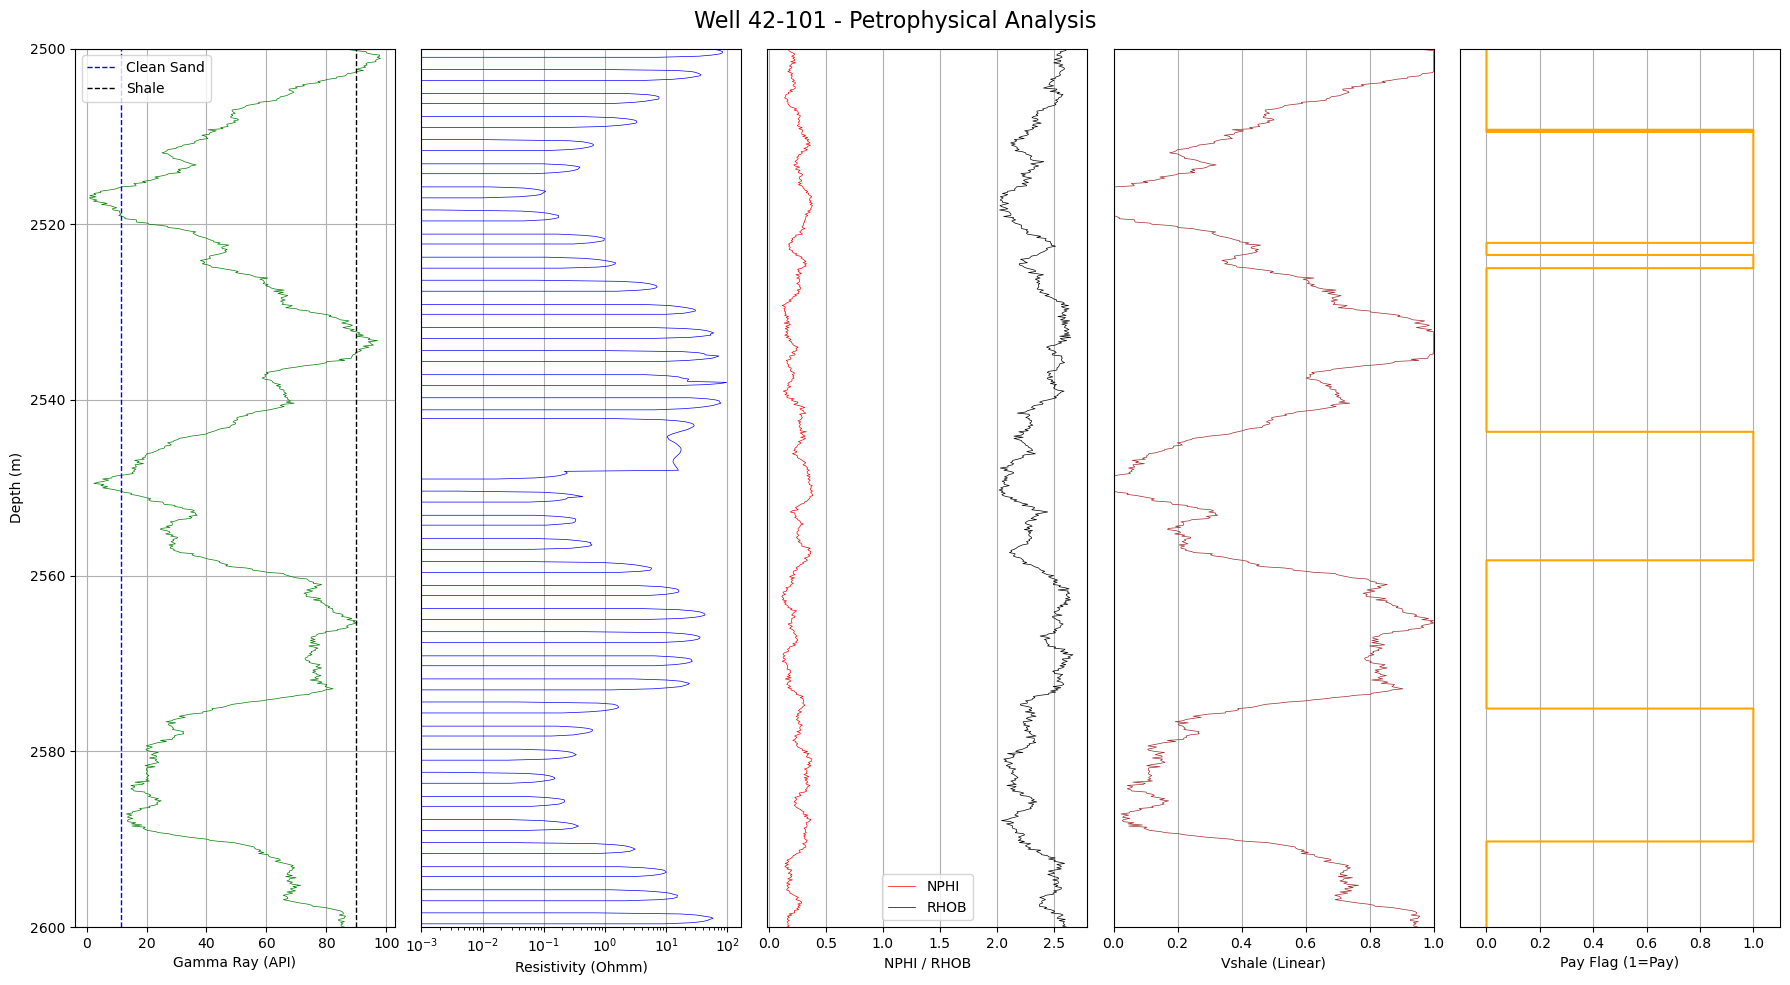


--- Petrophysical Summary ---
Net Pay Thickness: 44.0 m
Avg. Porosity in Pay Zone: 0.300 v/v
-----------------------------


In [8]:
# 1. Import the necessary libraries
import lasio
import pandas as pd
import matplotlib.pyplot as plt

# 2. Load the data (Replace 'well_42-101.las' with your actual file path)
las = lasio.read('well_42-101.las')
df = las.df()
df.reset_index(inplace=True)

# 3. Calculate Vshale from Gamma Ray
# Find the clean sand and shale baselines
gr_min = df['GR'].quantile(0.05)  # Assume clean sand at 5th percentile
gr_max = df['GR'].quantile(0.95)  # Assume shale at 95th percentile

print(f"GR min (clean): {gr_min:.1f}, GR max (shale): {gr_max:.1f}")

# Calculate Vshale using linear method
df['VSH_linear'] = (df['GR'] - gr_min) / (gr_max - gr_min)
# Ensure Vshale is between 0 and 1
df['VSH_linear'] = df['VSH_linear'].clip(lower=0, upper=1)

# 4. Create the multi-track plot from scratch
# Create a figure with 1 row and 5 columns of subplots
fig, axes = plt.subplots(1, 5, figsize=(18, 10))
fig.suptitle('Well 42-101 - Petrophysical Analysis', fontsize=16)

# Share the same depth (Y) axis across all plots and set limits
for ax in axes:
    ax.invert_yaxis() # Invert the Y-Axis so depth increases down
    ax.set_ylim(df['DEPT'].max(), df['DEPT'].min()) # Set depth range
    ax.grid(True)
    ax.yaxis.set_visible(False) # Turn off depth labels on all...

axes[0].yaxis.set_visible(True) # ...except the first plot

# Track 1: Gamma Ray with Sand/Shale lines
axes[0].plot(df['GR'], df['DEPT'], color='green', linewidth=0.5)
axes[0].axvline(gr_min, color='blue', linestyle='--', linewidth=1, label='Clean Sand')
axes[0].axvline(gr_max, color='black', linestyle='--', linewidth=1, label='Shale')
axes[0].set_xlabel('Gamma Ray (API)')
axes[0].legend()

# Track 2: Resistivity (Log Scale)
axes[1].plot(df['RT'], df['DEPT'], color='blue', linewidth=0.5)
axes[1].set_xlabel('Resistivity (Ohmm)')
axes[1].set_xscale('log') # Make it a logarithmic scale

# Track 3: Density Porosity
# Check if these curves exist in your LAS file first!
if 'NPHI' in df.columns:
    axes[2].plot(df['NPHI'], df['DEPT'], color='red', linewidth=0.5, label='NPHI')
if 'RHOB' in df.columns:
    axes[2].plot(df['RHOB'], df['DEPT'], color='black', linewidth=0.5, label='RHOB')
axes[2].set_xlabel('NPHI / RHOB')
axes[2].legend()

# Track 4: Calculated Vshale
axes[3].plot(df['VSH_linear'], df['DEPT'], color='brown', linewidth=0.5)
axes[3].set_xlabel('Vshale (Linear)')
axes[3].set_xlim(0, 1) # Set limits from 0 to 1 for Vshale

# Track 5: Interpreted Pay Zone
# Let's define a simple "pay" flag based on cutoffs Vshale < 0.4 and GR < 80
df['PAY'] = ((df['VSH_linear'] < 0.4) & (df['GR'] < 80)).astype(int)
axes[4].plot(df['PAY'], df['DEPT'], color='orange', linewidth=1.5, drawstyle='steps')
axes[4].set_xlabel('Pay Flag (1=Pay)')
axes[4].set_xlim(-0.1, 1.1) # Set limits to make the flag clear

# Add a depth label to the first track
axes[0].set_ylabel('Depth (m)')

# This command automatically adjusts spacing and then DISPLAYS the plot
plt.tight_layout()
plt.show()

# 5. Print a final summary report
net_pay_thickness = (df['PAY'].sum() * (df['DEPT'].diff().mean())) # Sum pay flags * average sample interval
avg_porosity_in_pay = df[df['PAY'] == 1]['NPHI'].mean() if 'NPHI' in df.columns else None

print("\n--- Petrophysical Summary ---")
print(f"Net Pay Thickness: {net_pay_thickness:.1f} m")
if avg_porosity_in_pay:
    print(f"Avg. Porosity in Pay Zone: {avg_porosity_in_pay:.3f} v/v")
print("-----------------------------")

### Objective: Write a single Python script that generates a complete petrophysical summary report for a well.

#### Your script must:

Load a LAS file of your choice using lasio.

Calculate a Vshale curve (using any method you choose: linear, Clavier, Larionov).

Calculate a Porosity curve (e.g., average of DPHI and NPHI, or from RHOB).

Identify a zone of interest by applying simple cutoffs (e.g., VSH < 0.4 and PHIE > 0.1).

Create a multi-track plot including: GR, Resistivity, Porosity, Vshale, and your interpreted zone.

Print a summary to the screen: average porosity and net thickness of your identified zone.

### This project uses everything we learned: pandas, lasio, matplotlib, and basic analysis.

### Where to Go From Here

### Practice: The best way to learn is by doing. Try the project on different wells.

#### Explore these powerful libraries:

#### seaborn: For beautiful statistical visualizations.

#### scikit-learn: For machine learning (e.g., facies classification from logs).

#### welly: A full-featured library specifically for well log analysis.

### Resources:

#### Website: Real Python

#### Book: Python for Data Analysis by Wes McKinney (creator of pandas)

#### Community: Stack Overflow, Subsurface Python Slack groups.

### Create a .csv file from the .LAS file

In [9]:
import pandas as pd

def las_to_csv(las_file_path, csv_file_path):
    """
    Convert a LAS file to CSV format and save it.
    
    Parameters:
        las_file_path (str): Path to the input LAS file
        csv_file_path (str): Path where the output CSV will be saved
    """
    try:
        # Read the LAS file using lasio library
        import lasio
        las = lasio.read(las_file_path)
        
        # Convert to pandas DataFrame
        df = las.df()
        
        # Add depth column (index is typically depth in LAS files)
        df.reset_index(inplace=True)
        df.rename(columns={'DEPT': 'DEPTH'}, inplace=True)
        
        # Save to CSV
        df.to_csv(csv_file_path, index=False)
        print(f"Successfully converted {las_file_path} to {csv_file_path}")
        
    except ImportError:
        print("Error: lasio library not found. Please install it with: pip install lasio")
    except Exception as e:
        print(f"An error occurred: {str(e)}")

# Example usage
if __name__ == "__main__":
    input_las = "well_42-101.las"   # Replace with your LAS file path
    output_csv = "well_42-101.csv"  # Replace with desired CSV output path
    las_to_csv(input_las, output_csv)

Successfully converted well_42-101.las to well_42-101.csv


### Project: Advanced Petrophysical Analysis 

=== LOADING AND EXPLORING well_42-101 ===
Data shape: (801, 6)

Column names:
['DEPTH', 'GR', 'RT', 'NPHI', 'RHOB', 'DPHI']

Basic statistics:
                 DEPTH              GR              RT            NPHI  \
count   801.0000000000  801.0000000000  801.0000000000  801.0000000000   
mean   2550.0000000000   50.1798740325    1.6471602871    0.2492098002   
std      28.9216344196   25.9820048586   21.0815774930    0.0657336288   
min    2500.0000000000    0.9304600000  -98.2082400000    0.1150800000   
25%    2525.0000000000   27.2980500000   -1.1067100000    0.1939900000   
50%    2550.0000000000   49.0442000000    0.0720700000    0.2491200000   
75%    2575.0000000000   73.7280600000    5.4908500000    0.2996200000   
max    2600.0000000000   98.0060300000   97.7537200000    0.3857400000   

                 RHOB            DPHI  
count  801.0000000000  801.0000000000  
mean     2.3609093883    0.1752062672  
std      0.1675963543    0.1015736299  
min      2.0204800000   -0.011

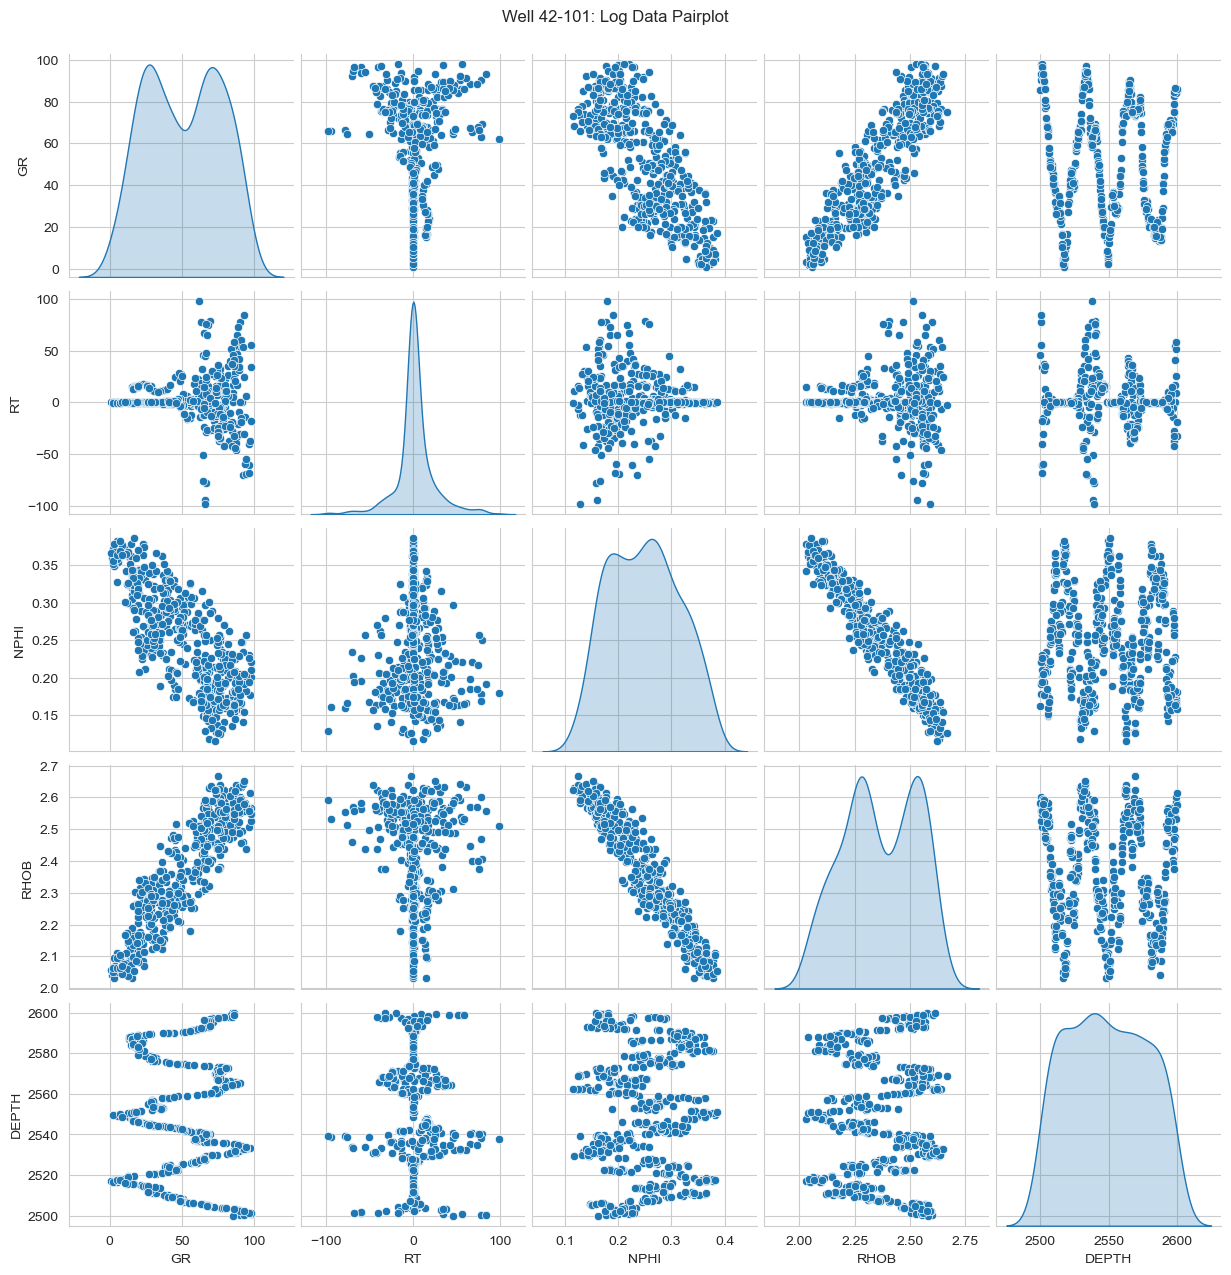


=== CORE PETROPHYSICAL ANALYSIS ===

=== FACIES CLASSIFICATION (scikit-learn) ===
Rows available for ML: 801


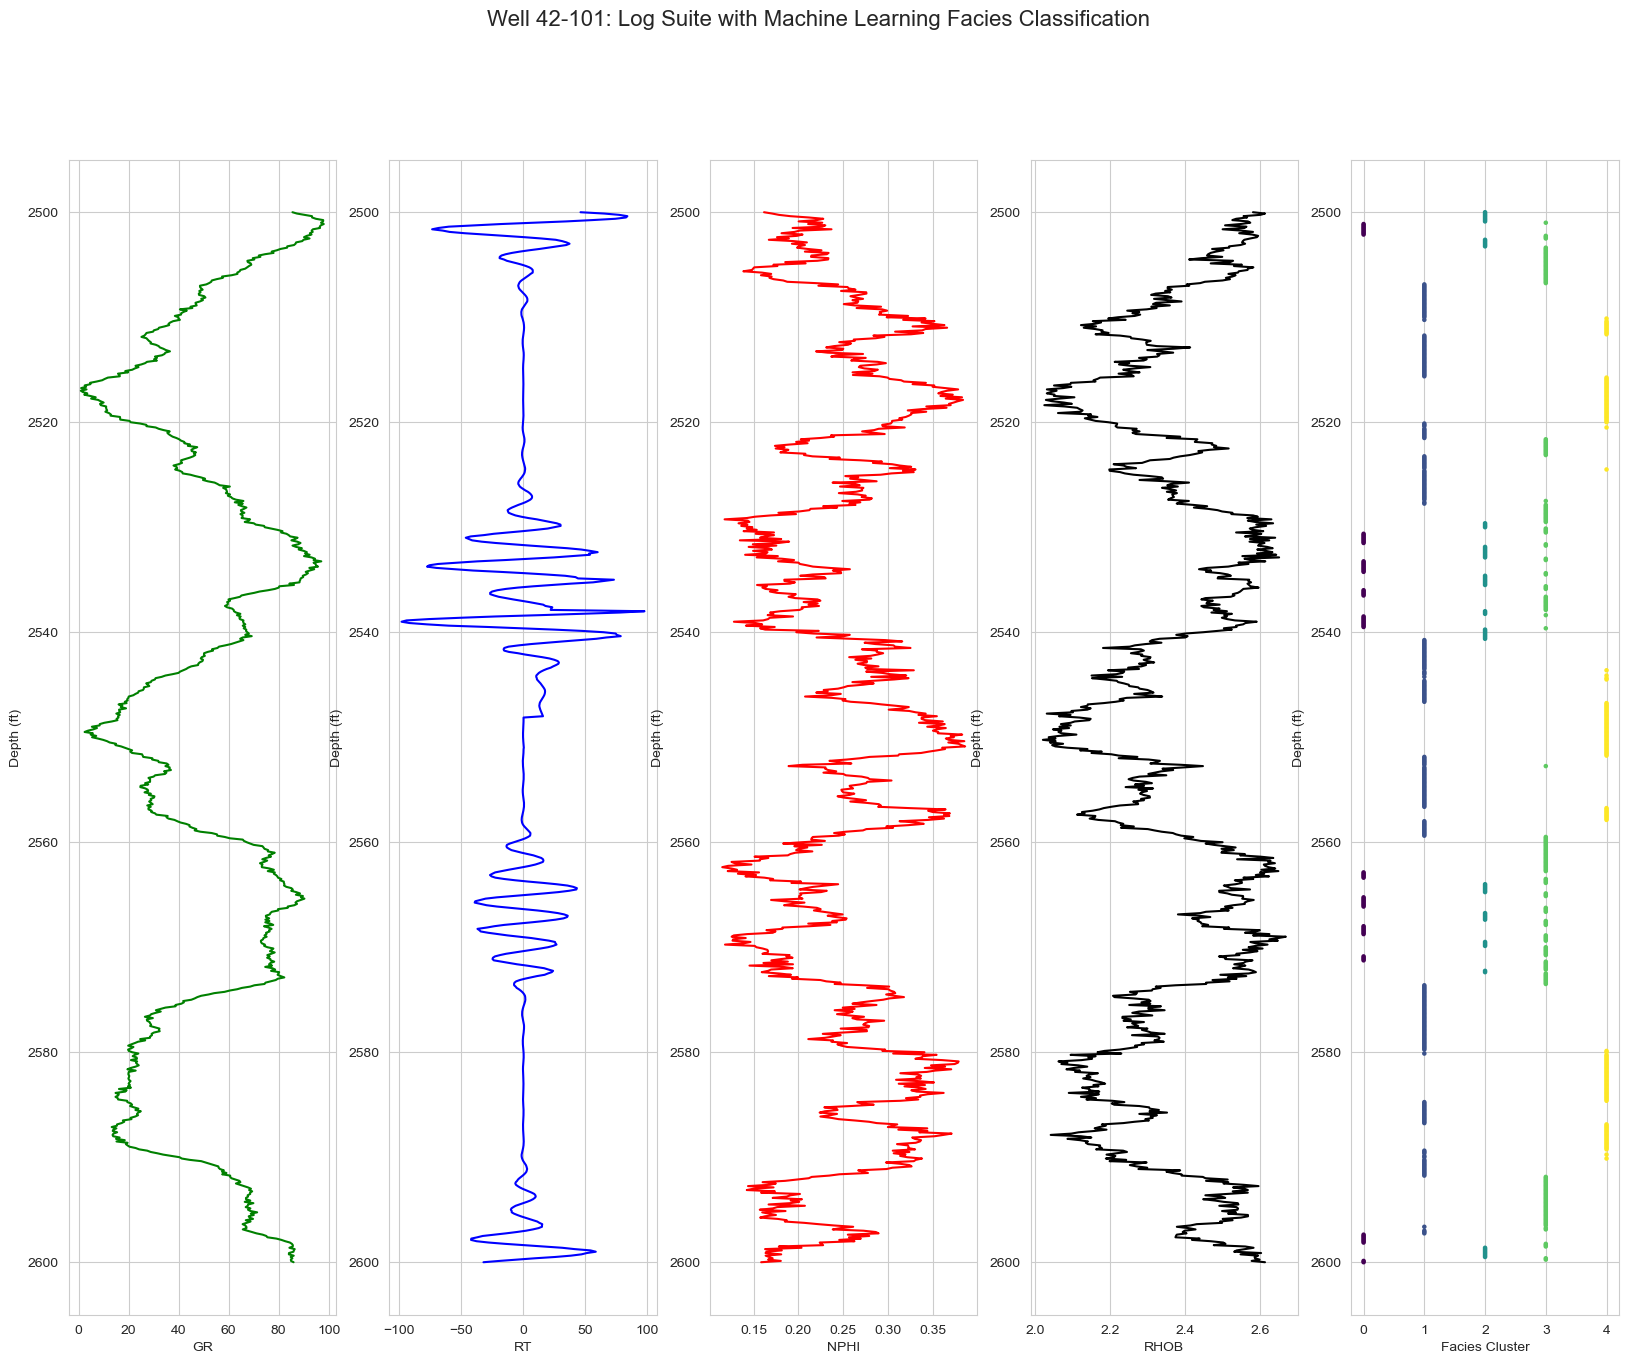


=== ADVANCED CROSSPLOTS (seaborn) ===


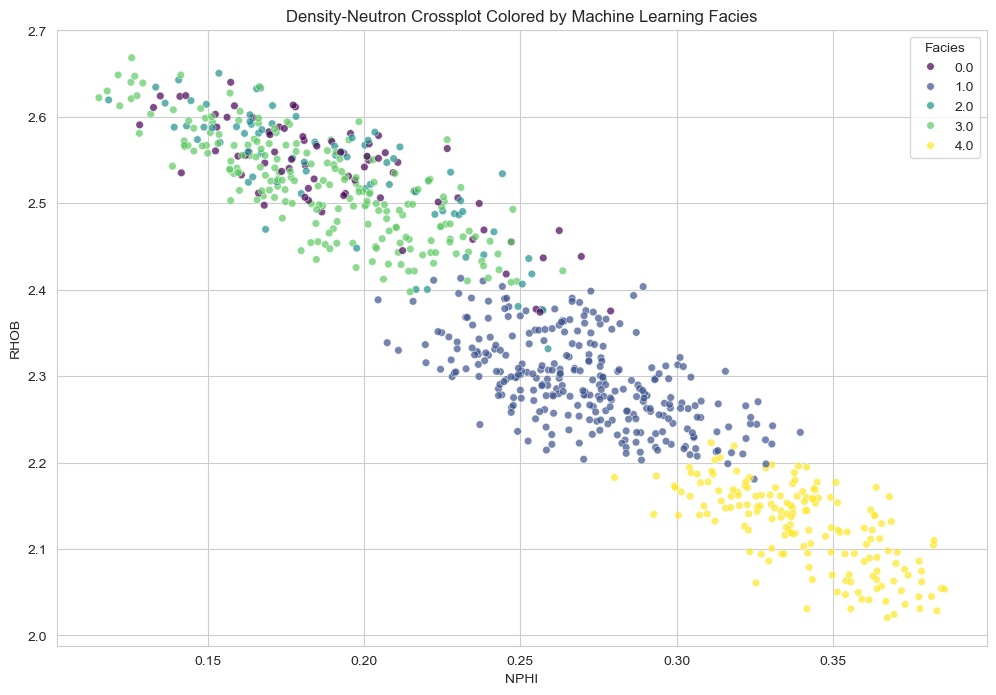


=== PROFESSIONAL WELL LOG HANDLING (welly) ===
Welly well object created with 4 curves
Depth range: 2500.0 to 2600.0 ft


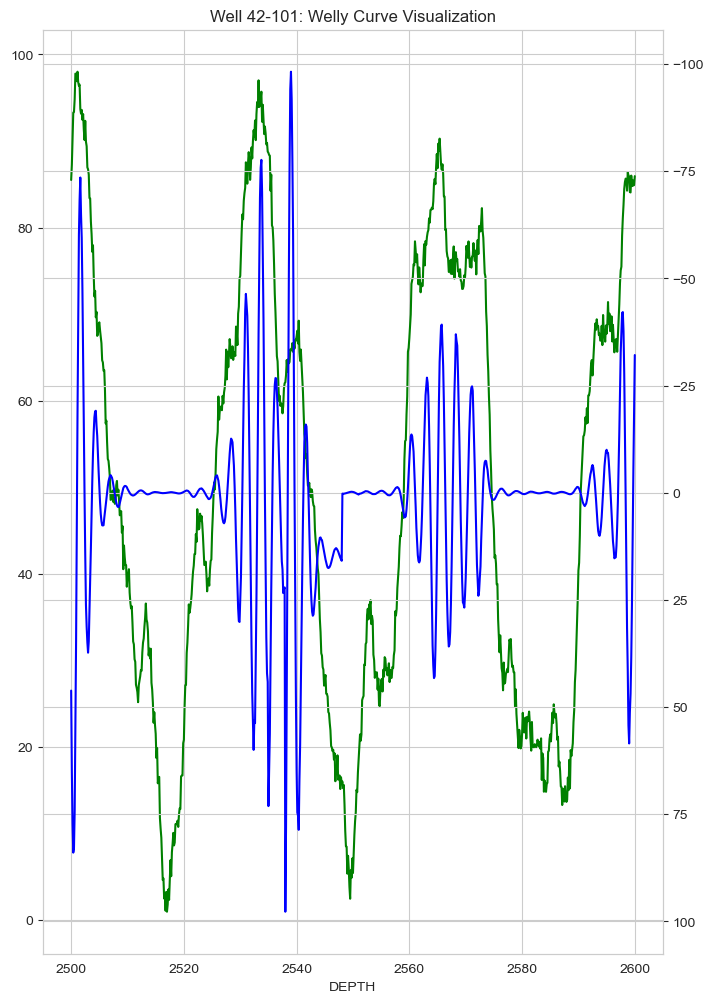


Welly Curve Statistics:
GR: min=0.93, max=98.01, mean=50.18
RT: min=-98.21, max=97.75, mean=1.65
NPHI: min=0.12, max=0.39, mean=0.25
RHOB: min=2.02, max=2.67, mean=2.36
Added smoothed GR curve to well object

=== SAVING RESULTS ===
Analysis complete! Results saved to well_42-101_analysis_results.csv

RECOMMENDATIONS FOR ANALYZING OTHER WELLS:
1. CHANGE PARAMETERS: Adjust rho_ma, rho_fl, gr_clean, gr_shale for different formations
2. TRY DIFFERENT CLUSTERS: Change n_clusters in KMeans() for more/less facies
3. ADD MORE FEATURES: Incorporate other logs like PEF, DTS, DTC if available
4. USE WELLY FOR: LAS file I/O, curve alignment, and professional workflows
5. EXPLORE OTHER ML MODELS: Gaussian Mixture Models, DBSCAN, or supervised learning
6. ADD FORMATION TOPS: Integrate with geological markers for zone-specific analysis


In [10]:
# Import the entire toolkit
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # For beautiful visualizations

# Machine learning for facies classification
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Welly for professional well log handling (if installed)
try:
    import welly
    from welly import Well, Curve
    WELLY_AVAILABLE = True
except ImportError:
    print("welly library not installed. Skipping welly-specific functionality.")
    WELLY_AVAILABLE = False

# Set visual style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

# --- 1. DATA LOADING & INITIAL EXPLORATION ---
print("=== LOADING AND EXPLORING well_42-101 ===")
df = pd.read_csv('well_42-101.csv')
print(f"Data shape: {df.shape}")
print("\nColumn names:")
print(df.columns.tolist())
print("\nBasic statistics:")
print(df.describe())

# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# --- 2. DATA QUALITY CHECK WITH SEABORN ---
print("\n=== DATA QUALITY VISUALIZATION (seaborn) ===")
# Create a pairplot to see relationships and distributions
# We'll use a smaller sample for speed
df_sample = df.sample(n=500, random_state=42) 
sns.pairplot(df_sample[['GR', 'RT', 'NPHI', 'RHOB', 'DEPTH']], diag_kind='kde')
plt.suptitle('Well 42-101: Log Data Pairplot', y=1.02)
plt.savefig('well_42-101_pairplot.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 3. CORE PETROPHYSICAL ANALYSIS ---
print("\n=== CORE PETROPHYSICAL ANALYSIS ===")
# Calculate VShale from GR
gr_clean = df['GR'].quantile(0.05)  # Use 5th percentile as clean
gr_shale = df['GR'].quantile(0.95)  # Use 95th percentile as shale
df['VSH_GR'] = (df['GR'] - gr_clean) / (gr_shale - gr_clean)
df['VSH_GR'] = np.clip(df['VSH_GR'], 0, 1)

# Calculate Density Porosity (assuming sandstone)
rho_ma = 2.65
rho_fl = 1.0
df['DPHI'] = (rho_ma - df['RHOB']) / (rho_ma - rho_fl)

# Calculate Effective Porosity (shale corrected)
nphi_shale = df[df['VSH_GR'] > 0.7]['NPHI'].mean()
df['PHIE'] = df['NPHI'] - (df['VSH_GR'] * nphi_shale)
df['PHIE'] = df['PHIE'].clip(lower=0.0, upper=0.4)

# --- 4. MACHINE LEARNING FACIES CLASSIFICATION (scikit-learn) ---
print("\n=== FACIES CLASSIFICATION (scikit-learn) ===")
# Select features for clustering
features = ['GR', 'RT', 'NPHI', 'RHOB', 'DPHI']
X = df[features].copy()

# Handle missing values by dropping rows with any NaN in these features
X.dropna(inplace=True)
print(f"Rows available for ML: {len(X)}")

# Standardize the features (crucial for K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform K-Means clustering (let's try 5 facies)
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df.loc[X.index, 'Facies'] = kmeans.fit_predict(X_scaled)

# Visualize facies in depth plot
fig, axes = plt.subplots(1, 5, figsize=(20, 15))
logs = ['GR', 'RT', 'NPHI', 'RHOB', 'Facies']
colors = ['green', 'blue', 'red', 'black', 'tab:blue']

for i, (log, color) in enumerate(zip(logs, colors)):
    ax = axes[i]
    if log == 'Facies':
        ax.scatter(df['Facies'], df['DEPTH'], c=df['Facies'], cmap='viridis', s=5)
        ax.set_xlabel('Facies Cluster')
    else:
        ax.plot(df[log], df['DEPTH'], color=color)
        ax.set_xlabel(log)
    ax.set_ylabel('Depth (ft)')
    ax.grid(True)
    ax.invert_yaxis()

plt.suptitle('Well 42-101: Log Suite with Machine Learning Facies Classification', fontsize=16)
plt.savefig('well_42-101_facies.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 5. ADVANCED VISUALIZATION WITH SEABORN ---
print("\n=== ADVANCED CROSSPLOTS (seaborn) ===")
# Create a crossplot colored by facies
plt.figure(figsize=(12, 8))
scatter = sns.scatterplot(data=df.dropna(subset=['Facies']), x='NPHI', y='RHOB', 
                          hue='Facies', palette='viridis', alpha=0.7, s=30)
plt.title('Density-Neutron Crossplot Colored by Machine Learning Facies')
plt.savefig('well_42-101_facies_crossplot.png', dpi=300, bbox_inches='tight')
plt.show()

# --- 6. WELLY INTEGRATION (If available) ---
if WELLY_AVAILABLE:
    print("\n=== PROFESSIONAL WELL LOG HANDLING (welly) ===")
    try:
        # Create a welly Well object properly
        # Welly expects a dictionary of curves with depth as index
        curves_dict = {}
        
        for curve_name in ['GR', 'RT', 'NPHI', 'RHOB']:
            if curve_name in df.columns:
                # Create Series with DEPTH as index
                curve_series = df.set_index('DEPTH')[curve_name].dropna()
                curves_dict[curve_name] = curve_series
        
        # Create the well object with the curves dictionary
        w = Well({})
        w.data = curves_dict
        
        # Basic welly operations - now these will work
        print(f"Welly well object created with {len(w.data)} curves")
        
        # Get depth range from the index of the first curve
        if w.data:
            first_curve_name = list(w.data.keys())[0]
            depth_index = w.data[first_curve_name].index
            print(f"Depth range: {depth_index.min():.1f} to {depth_index.max():.1f} ft")
        
        # Example: Use welly to quickly visualize multiple curves
        fig, ax = plt.subplots(figsize=(8, 12))
        
        # Plot GR curve using welly
        if 'GR' in w.data:
            ax = w.data['GR'].plot(ax=ax, c='green', label='GR')
        if 'RT' in w.data:
            ax = w.data['RT'].plot(ax=ax, c='blue', label='RT', secondary_y=True)
        
        ax.invert_yaxis()
        ax.grid(True)
        ax.set_title('Well 42-101: Welly Curve Visualization')
        plt.savefig('well_42-101_welly_plot.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        # Example: Welly's built-in curve statistics
        print("\nWelly Curve Statistics:")
        for curve_name, curve_data in w.data.items():
            print(f"{curve_name}: min={curve_data.min():.2f}, max={curve_data.max():.2f}, mean={curve_data.mean():.2f}")
            
        # Example: Curve smoothing with welly
        if 'GR' in w.data:
            # Apply a simple smoothing filter
            gr_smoothed = w.data['GR'].rolling(window=5, center=True).mean()
            w.data['GR_SMOOTH'] = gr_smoothed
            print("Added smoothed GR curve to well object")
        
    except Exception as e:
        print(f"Error with welly operations: {e}")
        import traceback
        traceback.print_exc()

# --- 7. SAVE RESULTS ---
print("\n=== SAVING RESULTS ===")
# Save the enhanced dataframe with new curves
output_filename = 'well_42-101_analysis_results.csv'
df.to_csv(output_filename, index=False)
print(f"Analysis complete! Results saved to {output_filename}")

# --- 8. RECOMMENDATIONS FOR OTHER WELLS ---
print("\n" + "="*60)
print("RECOMMENDATIONS FOR ANALYZING OTHER WELLS:")
print("="*60)
print("1. CHANGE PARAMETERS: Adjust rho_ma, rho_fl, gr_clean, gr_shale for different formations")
print("2. TRY DIFFERENT CLUSTERS: Change n_clusters in KMeans() for more/less facies")
print("3. ADD MORE FEATURES: Incorporate other logs like PEF, DTS, DTC if available")
print("4. USE WELLY FOR: LAS file I/O, curve alignment, and professional workflows")
print("5. EXPLORE OTHER ML MODELS: Gaussian Mixture Models, DBSCAN, or supervised learning")
print("6. ADD FORMATION TOPS: Integrate with geological markers for zone-specific analysis")